# Chapitre 5 - Cours 1 : réplication à leader unique

Répliquer, c'est garder une copie des mêmes données sur plusieurs machines reliées par
un réseau. Tant que les données ne changent pas, c'est trivial : on copie une fois. Toute
la difficulté vient des **modifications**. Ce premier cours étudie la famille la plus
répandue, la réplication à **leader unique** (leader-based, primary-backup,
active/passive) : un nœud reçoit toutes les écritures et les transmet aux autres. Il
couvre l'introduction du chapitre et la section *Leaders and Followers* jusqu'à
*Handling Node Outages* inclus.

**Plan.**

1. Trois raisons de répliquer, et le schéma leader-suiveurs.
2. Synchrone, asynchrone, semi-synchrone : latence et disponibilité des écritures.
3. Ajouter un suiveur sans arrêter le leader.
4. Panne d'un suiveur : le rattrapage.
5. Panne du leader : le basculement et les écritures perdues.
6. Split brain, fencing et clés réutilisées.

Les simulations reposent sur le simulateur à événements `ddia.sim` et sur le module
[`ddia/replication.py`](../../ddia/replication.py) (classes `ReplNode`, `Controller`,
`WriterClient`, fonction `failover_scenario`).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import replication as rp
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Trois raisons de répliquer (introduction du chapitre)

On réplique pour trois raisons, qui reviendront tout au long du chapitre :

- **latence** : garder les données près des utilisateurs (une réplique par continent) ;
- **disponibilité et durabilité** : continuer à servir, et ne rien perdre, quand une
  machine (ou tout un centre de données) tombe ;
- **débit de lecture** : multiplier les machines qui répondent aux lectures.

Ce chapitre suppose que chaque machine peut contenir **toute** la base ; découper une
base trop grosse est l'objet du chapitre 6. Il étudie trois familles
d'algorithmes, que presque toutes les bases distribuées utilisent : leader unique,
multi-leader et sans leader.

**Le schéma leader-suiveurs.** Une réplique est désignée **leader** (ou primaire) :
toutes les écritures des clients passent par elle. Elle les applique à son stockage
local puis les envoie aux autres répliques, les **suiveurs** (followers, réplicas de
lecture, secondaires), sous la forme d'un **journal de réplication** (flux de
changements). Chaque suiveur applique les écritures **dans le même ordre** que le leader.
Les lectures peuvent aller au leader ou à n'importe quel suiveur. C'est le fonctionnement
par défaut de PostgreSQL, MySQL, Oracle Data Guard, SQL Server, MongoDB, et aussi de
Kafka.

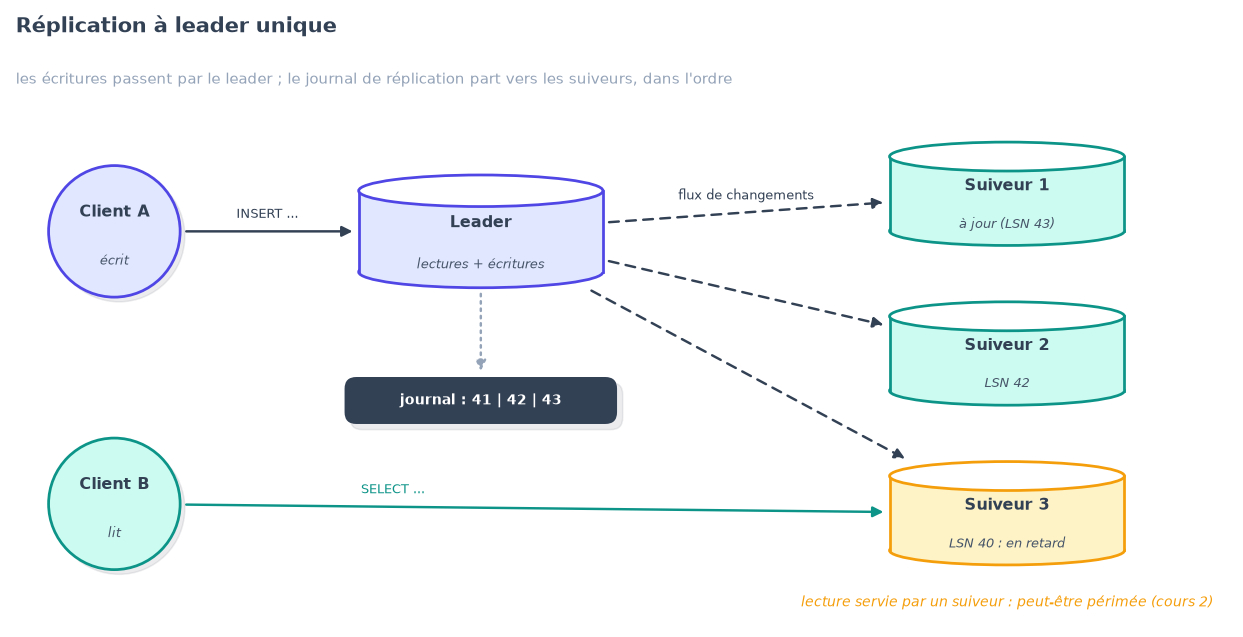

In [2]:
d = Diagram(13, 5.6, title="Réplication à leader unique",
            subtitle="les écritures passent par le leader ; le journal de réplication part vers les suiveurs, dans l'ordre")
d.box("w", 1.1, 4.2, "Client A", sub="écrit", kind="user", w=1.4, color=INDIGO)
d.box("r1", 1.1, 1.3, "Client B", sub="lit", kind="user", w=1.4, color=TEAL)
d.box("L", 5.0, 4.2, "Leader", sub="lectures + écritures", color=INDIGO, kind="db", w=2.6, h=1.2)
d.box("log", 5.0, 2.4, "journal : 41 | 42 | 43", color=SLATE, kind="tag", w=2.9, h=0.5, fontsize=9)
for i, (y, sub) in enumerate([(4.6, "à jour (LSN 43)"), (2.9, "LSN 42"), (1.2, "LSN 40 : en retard")]):
    d.box(f"f{i}", 10.6, y, f"Suiveur {i + 1}", sub=sub, color=[TEAL, TEAL, AMBER][i], kind="db", w=2.5, h=1.1)
    d.arrow("L", f"f{i}", "flux de changements" if i == 0 else None, style="dashed", color=SLATE)
d.arrow("w", "L", "INSERT ... ")
d.arrow("r1", "f2", "SELECT ...", color=TEAL, label_pos=0.3)
d.arrow("L", "log", style="dotted", color=GRAY)
d.note(10.6, 0.25, "lecture servie par un suiveur : peut-être périmée (cours 2)", color=AMBER)
d.show()

> **À retenir.** On réplique pour la latence, la disponibilité et le débit de lecture.
> Avec un leader unique, l'ordre des écritures est décidé à un seul endroit, puis
> recopié tel quel : c'est ce qui rend ce schéma simple à comprendre.

## 2. Synchrone ou asynchrone (section *Synchronous Versus Asynchronous Replication*)

Quand le leader répond-il « c'est enregistré » au client ?

- **synchrone** : après qu'un suiveur a confirmé avoir reçu l'écriture. Le suiveur est
  garanti à jour : si le leader meurt, rien n'est perdu ;
- **asynchrone** : tout de suite, sans attendre. Le leader n'est jamais ralenti par un
  suiveur, mais une écriture confirmée peut n'exister **que** sur le leader.

Le diagramme espace-temps ci-dessous montre une écriture avec un suiveur synchrone et un
suiveur asynchrone : le client attend l'acquittement du suiveur 1, pas celui du
suiveur 2, qui applique l'écriture bien plus tard.

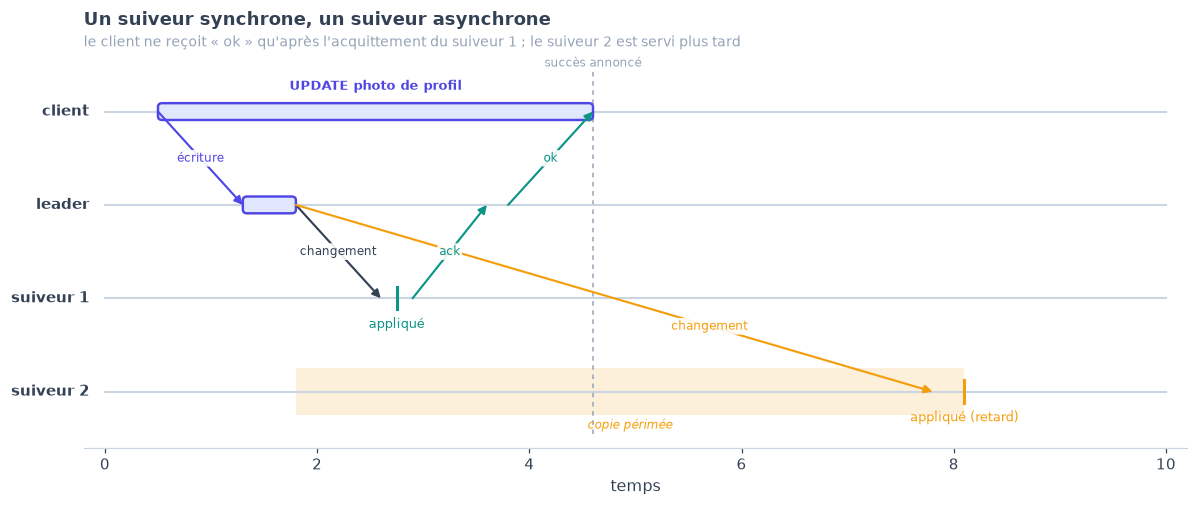

In [3]:
st = SpaceTime(["client", "leader", "suiveur 1", "suiveur 2"], t_max=10, width=11,
               title="Un suiveur synchrone, un suiveur asynchrone",
               subtitle="le client ne reçoit « ok » qu'après l'acquittement du suiveur 1 ; le suiveur 2 est servi plus tard")
st.op("client", 0.5, 4.6, "UPDATE photo de profil", color=INDIGO)
st.msg("client", 0.5, "leader", 1.3, "écriture", color=INDIGO)
st.op("leader", 1.3, 1.8, "", color=INDIGO)
st.msg("leader", 1.8, "suiveur 1", 2.6, "changement", color=SLATE)
st.msg("suiveur 1", 2.9, "leader", 3.6, "ack", color=TEAL)
st.msg("leader", 3.8, "client", 4.6, "ok", color=TEAL)
st.msg("leader", 1.8, "suiveur 2", 7.8, "changement", color=AMBER, label_pos=0.65)
st.event("suiveur 1", 2.75, "appliqué", kind="tick", color=TEAL)
st.event("suiveur 2", 8.1, "appliqué (retard)", kind="tick", color=AMBER)
st.span("suiveur 2", 1.8, 8.1, "copie périmée", color=AMBER, alpha=0.15)
st.vline(4.6, "succès annoncé")
st.show()

**Tout synchrone est impraticable.** Si le leader attendait tous ses suiveurs, une seule
panne bloquerait toutes les écritures, et la latence serait celle du **plus lent**
suiveur. En pratique, « synchrone » veut souvent dire **semi-synchrone** : un suiveur
synchrone, les autres asynchrones ; si le synchrone faiblit, un asynchrone prend sa
place. On a ainsi toujours deux copies à jour (le leader et ce suiveur). Variante : un
**quorum** de répliques (par exemple 3 sur 5, leader compris) est mis à jour de façon
synchrone, idée centrale des sections sans leader (cours 4) et du consensus (chapitre
9).

Quantifions avec des **statistiques d'ordre**. Si le leader envoie l'écriture à $k$
suiveurs en parallèle et attend $m$ acquittements, la latence ajoutée est le $m$-ième
plus petit des $k$ allers-retours (fonction `rp.write_latency_samples`). Modélisons
l'aller-retour vers un suiveur du même centre de données par une loi log-normale de médiane 1 ms ;
avec probabilité 2 %, le suiveur traverse un mauvais moment (pause GC, disque saturé) et
répond en 50 à 200 ms.

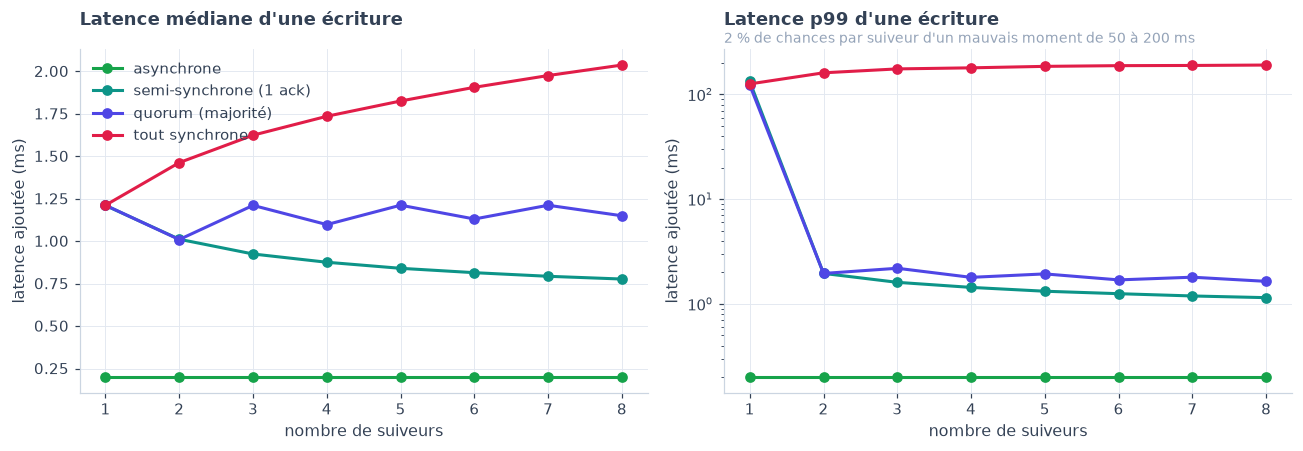

mode,asynchrone,quorum (majorité),semi-synchrone (1 ack),tout synchrone
suiveurs,,,,
1,0.2,123.0,132.7,125.8
2,0.2,2.0,2.0,160.6
4,0.2,1.8,1.4,179.2
8,0.2,1.6,1.1,190.5


In [4]:
def rtt(n, k, rng):
    base = rng.lognormal(np.log(1.0), 0.4, (n, k))
    bad = rng.random((n, k)) < 0.02
    return np.where(bad, rng.uniform(50, 200, (n, k)), base)

modes = {"async": "asynchrone", "semisync": "semi-synchrone (1 ack)", "quorum": "quorum (majorité)",
         "sync": "tout synchrone"}
colors = {"async": GREEN, "semisync": TEAL, "quorum": INDIGO, "sync": ROSE}
ks = range(1, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
rows = []
for m, lab in modes.items():
    p50, p99 = [], []
    for k in ks:
        lat = rp.write_latency_samples(m, k, rtt(40000, k, rng), local=0.2)
        p50.append(np.percentile(lat, 50)); p99.append(np.percentile(lat, 99))
        rows.append({"mode": lab, "suiveurs": k, "p50 (ms)": p50[-1], "p99 (ms)": p99[-1]})
    axes[0].plot(ks, p50, "o-", color=colors[m], label=lab)
    axes[1].plot(ks, p99, "o-", color=colors[m], label=lab)
axes[0].set_title("Latence médiane d'une écriture"); axes[1].set_title("Latence p99 d'une écriture")
for ax in axes:
    ax.set_xlabel("nombre de suiveurs"); ax.set_ylabel("latence ajoutée (ms)")
axes[1].set_yscale("log")
axes[0].legend()
subtitle(axes[1], "2 % de chances par suiveur d'un mauvais moment de 50 à 200 ms")
finish(fig)
plt.show()
pd.DataFrame(rows).pivot(index="suiveurs", columns="mode", values="p99 (ms)").round(1).loc[[1, 2, 4, 8]]

Lecture des courbes :

- la **médiane** bouge peu : attendre le plus lent de 8 suiveurs coûte environ 1 ms de
  plus qu'attendre le plus rapide ;
- le **p99** sépare les modes : en tout synchrone, la probabilité qu'**au moins un**
  suiveur soit lent, $1 - 0{,}98^k$, dépasse toujours 1 % : le centile 99 est dicté par
  le mauvais moment d'un seul suiveur (plus de 50 ms) et empire avec $k$. Le
  semi-synchrone, lui, **profite** de la redondance : il faudrait que tous les suiveurs
  soient lents à la fois ($0{,}02^k$, sous 1 % dès 2 suiveurs). Le quorum est entre les
  deux : avec un seul suiveur, il se confond avec les deux autres modes ;
- l'asynchrone ne paie que l'écriture locale.

Même calcul pour la **disponibilité des écritures** : si chaque suiveur est disponible
avec probabilité $a$, les écritures sont possibles avec probabilité $a^k$ en tout
synchrone, $1-(1-a)^k$ en semi-synchrone (on promeut un autre suiveur synchrone), et
$P(\text{au moins } \lceil k/2 \rceil \text{ sur } k)$ pour un quorum majoritaire.

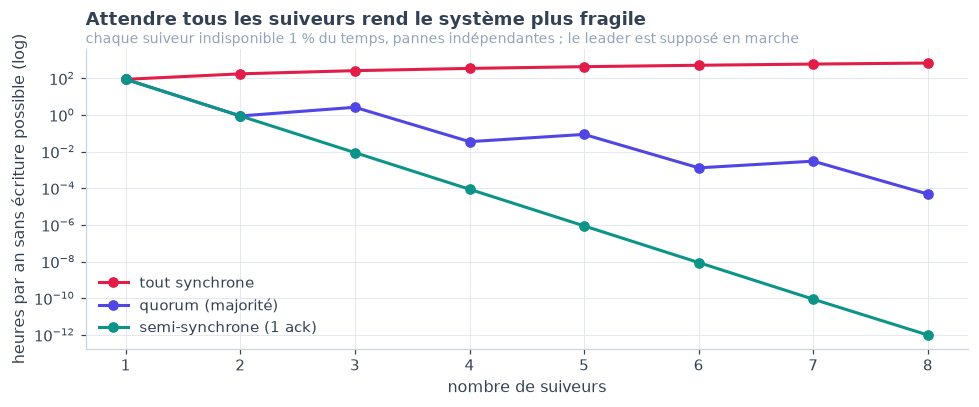

In [5]:
a = 0.99
fig, ax = plt.subplots(figsize=(9, 3.8))
for m, f in {"sync": lambda k: a ** k,
             "quorum": lambda k: rp.k_of_n(a, rp.needed_acks("quorum", k), k),
             "semisync": lambda k: 1 - (1 - a) ** k}.items():
    ax.plot(list(ks), [(1 - f(k)) * 365 * 24 for k in ks], "o-", color=colors[m], label=modes[m])
ax.set_yscale("log")
ax.set_xlabel("nombre de suiveurs"); ax.set_ylabel("heures par an sans écriture possible (log)")
ax.set_title("Attendre tous les suiveurs rend le système plus fragile")
subtitle(ax, "chaque suiveur indisponible 1 % du temps, pannes indépendantes ; le leader est supposé en marche")
ax.legend()
plt.tight_layout(); plt.show()

En tout synchrone, ajouter des suiveurs **dégrade** la disponibilité des écritures (88 h
par an avec un suiveur, plus de 600 h avec huit) ; en semi-synchrone ou par quorum,
chaque suiveur supplémentaire l'améliore. Voilà pourquoi la réplication **totalement
asynchrone** reste très utilisée, surtout avec beaucoup de suiveurs ou des suiveurs
lointains : le leader continue d'écrire même si tous les suiveurs sont à la traîne, au
prix d'une **durabilité affaiblie** (une écriture confirmée peut être perdue, section 5).

> **À retenir.** Synchrone = durabilité, mais latence et disponibilité dictées par les
> suiveurs attendus ; asynchrone = rapide et disponible, mais une écriture confirmée
> peut disparaître avec le leader. Le semi-synchrone (ou un quorum) n'attend que les
> plus rapides : il garde une copie à jour sans dépendre du plus lent.

## 3. Ajouter un suiveur sans arrêter le leader (section *Setting Up New Followers*)

Copier les fichiers de la base ne suffit pas : les clients écrivent pendant la copie, qui
verrait différentes parties de la base à différents instants. Verrouiller la base pendant
la copie irait contre la disponibilité. La recette standard :

1. prendre un **instantané cohérent** du leader, sans le bloquer (c'est aussi ce que
   fait une sauvegarde) ;
2. copier l'instantané sur le nouveau nœud ;
3. le suiveur demande au leader **toutes les modifications depuis l'instantané**, ce qui
   suppose que l'instantané soit associé à une **position exacte** du journal (le *log
   sequence number* de PostgreSQL, les coordonnées de binlog ou les GTID de MySQL) ;
4. une fois l'arriéré appliqué, le suiveur a **rattrapé** le leader et suit le flux.

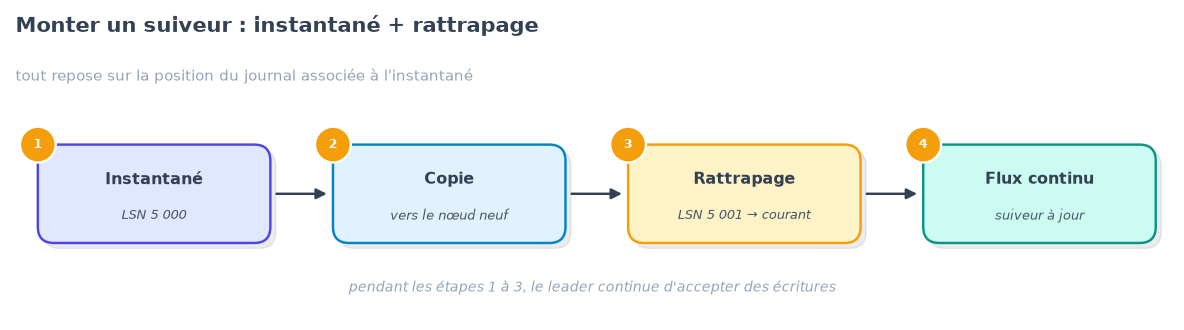

In [6]:
d = Diagram(13, 2.5, title="Monter un suiveur : instantané + rattrapage",
            subtitle="tout repose sur la position du journal associée à l'instantané")
names = d.flow([("s1", "Instantané", "LSN 5 000"), ("s2", "Copie", "vers le nœud neuf"),
                ("s3", "Rattrapage", "LSN 5 001 → courant"), ("s4", "Flux continu", "suiveur à jour")],
               y=1.4, x0=1.6, dx=3.3, colors=[INDIGO, SKY, AMBER, TEAL], w=2.6, h=1.1)
for i, n in enumerate(names):
    d.badge(1.6 + i * 3.3 - 1.3, 1.95, str(i + 1))
d.note(6.5, 0.35, "pendant les étapes 1 à 3, le leader continue d'accepter des écritures", color=GRAY)
d.show()

**Combien de temps dure le rattrapage ?** Pendant la copie (durée $T_c$), le leader
accumule $\lambda T_c$ écritures, où $\lambda$ est son débit d'écriture. Le suiveur les
applique au débit $\mu$ tandis que $\lambda$ nouvelles arrivent chaque seconde : l'arriéré
diminue à la vitesse $\mu - \lambda$, d'où un rattrapage en

$$T_r = \frac{\lambda\, T_c}{\mu - \lambda} = \frac{T_c}{\mu/\lambda - 1}.$$

Si le suiveur n'applique que 10 % plus vite que le leader n'écrit, le rattrapage dure
**dix fois** la copie ; s'il est plus lent ($\mu \le \lambda$), il ne rattrape jamais.

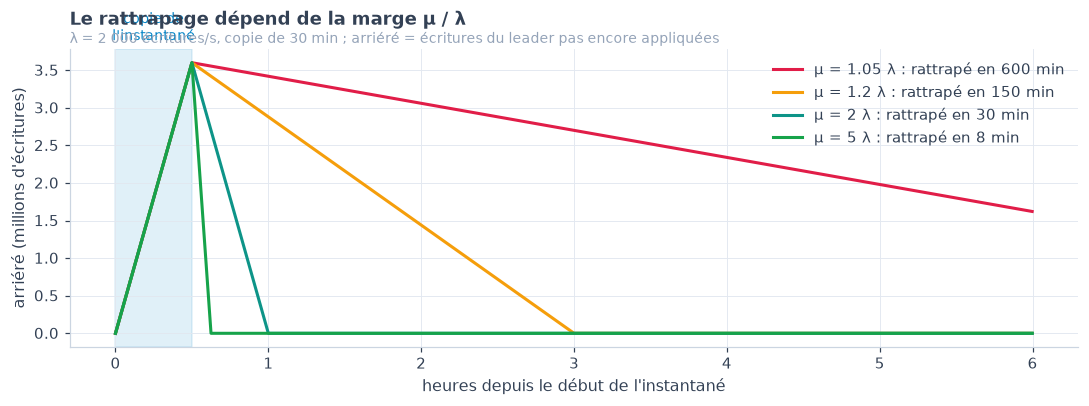

In [7]:
lam, Tc = 2000, 1800                 # 2 000 écritures/s, 30 min de copie
t = np.arange(0, 6 * 3600, 10.0)
fig, ax = plt.subplots(figsize=(10, 3.8))
for ratio, c in [(1.05, ROSE), (1.2, AMBER), (2.0, TEAL), (5.0, GREEN)]:
    mu = ratio * lam
    backlog = np.where(t < Tc, lam * t, np.maximum(0, lam * Tc - (mu - lam) * (t - Tc)))
    Tr = Tc / (ratio - 1)
    ax.plot(t / 3600, backlog / 1e6, color=c, label=f"μ = {ratio:g} λ : rattrapé en {Tr / 60:.0f} min")
ax.axvspan(0, Tc / 3600, color=SKY, alpha=0.12)
ax.text(Tc / 7200, 3.9, "copie de\nl'instantané", ha="center", fontsize=9, color=SKY)
ax.set_xlabel("heures depuis le début de l'instantané"); ax.set_ylabel("arriéré (millions d'écritures)")
ax.set_title("Le rattrapage dépend de la marge μ / λ")
subtitle(ax, "λ = 2 000 écritures/s, copie de 30 min ; arriéré = écritures du leader pas encore appliquées")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

> **À retenir.** Un nouveau suiveur = un instantané cohérent **repéré dans le journal**,
> puis le rejeu de tout ce qui a suivi. Le rattrapage n'est rapide que si le suiveur
> applique nettement plus vite que le leader n'écrit.

## 4. Panne d'un suiveur : le rattrapage (section *Follower failure: Catch-up recovery*)

Chaque suiveur garde sur disque le journal des modifications reçues. Après un
redémarrage ou une coupure réseau, il sait quelle est la dernière transaction appliquée
et demande au leader **la suite**. Rejouons-le sur le simulateur : le suiveur `n3` tombe
à t = 2 et redémarre à t = 4 ; il envoie alors `fetch(lsn)` et reçoit tout l'arriéré.

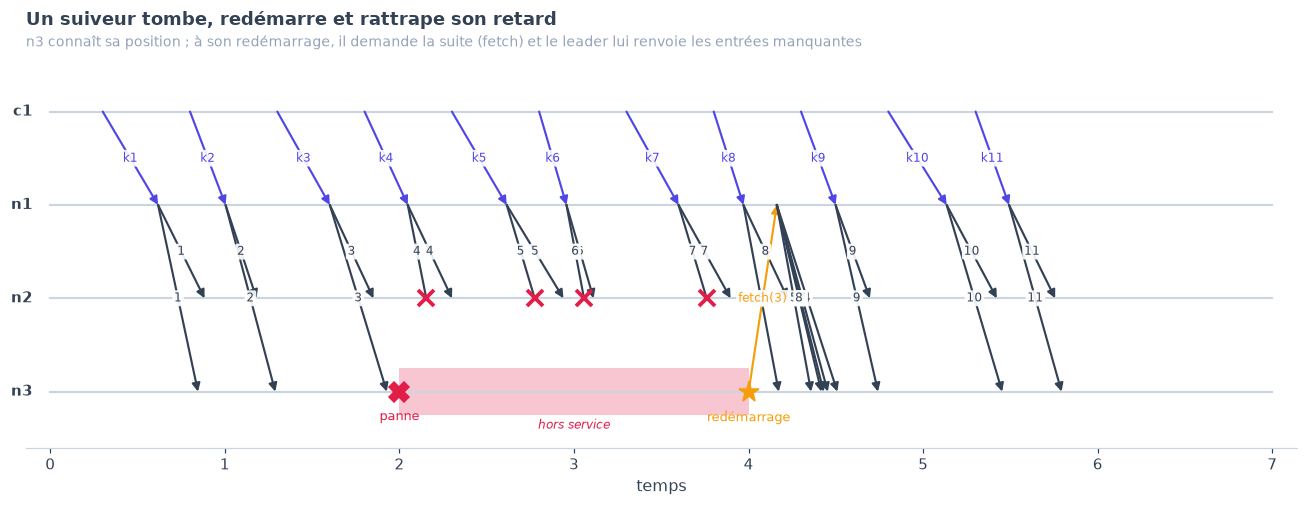

,n1,n2,n3
LSN final,11,11,11
clés,11,11,11


In [8]:

net = Network(seed=2, latency=(0.15, 0.35))
names = ["n1", "n2", "n3"]
nodes = {n: net.add(rp.ReplNode(n, names, leader="n1", mode="async")) for n in names}
ctrl = net.add(rp.Controller("controleur", names, "n1", ["c1"], timeout=50))
cli = net.add(rp.WriterClient("c1", "n1", period=0.5, start=0.3, stop=5.6))
net.at(2.0, net.crash, "n3")
net.at(4.0, net.recover, "n3")
net.run(until=7)
kinds = {"write": INDIGO, "ok": TEAL, "repl": SLATE, "fetch": AMBER, "ack": GRAY}
st = SpaceTime(["c1", "n1", "n2", "n3"], t_max=7, width=12,
               title="Un suiveur tombe, redémarre et rattrape son retard",
               subtitle="n3 connaît sa position ; à son redémarrage, il demande la suite (fetch) et le leader lui renvoie les entrées manquantes")
st.from_trace([x for x in net.trace if x.msg[0] in ("write", "repl", "fetch") and x.src != "controleur"],
              color_of=lambda x: kinds[x.msg[0]],
              label_of=lambda x: (f"k{x.msg[3]}" if x.msg[0] == "write" else
                                  f"{x.msg[2].lsn}" if x.msg[0] == "repl" else f"fetch({x.msg[1]})"))
st.event("n3", 2.0, "panne", kind="crash")
st.span("n3", 2.0, 4.0, "hors service", color=ROSE)
st.event("n3", 4.0, "redémarrage", kind="star")
st.show()
pd.DataFrame({n: [x.lsn, len(x.data)] for n, x in nodes.items()}, index=["LSN final", "clés"])

Les entrées envoyées à `n3` pendant sa panne sont perdues (croix rouges) ; au
redémarrage, un seul message `fetch(3)` suffit à tout récupérer, et les trois nœuds
finissent avec le même journal. Simple sur le papier, ce rattrapage pèse en pratique :
après une longue absence sous forte charge d'écriture, le suiveur **et** le leader (qui
doit relire et renvoyer l'arriéré) sont fortement sollicités.

**Le dilemme du leader.** Le leader ne peut effacer une partie de son journal qu'une
fois **tous** les suiveurs passés au-delà. Si un suiveur reste absent longtemps : soit
il garde le journal (au risque de remplir son disque), soit il l'efface et le suiveur
devra être reconstruit depuis une sauvegarde (section 3). Ordre de grandeur :

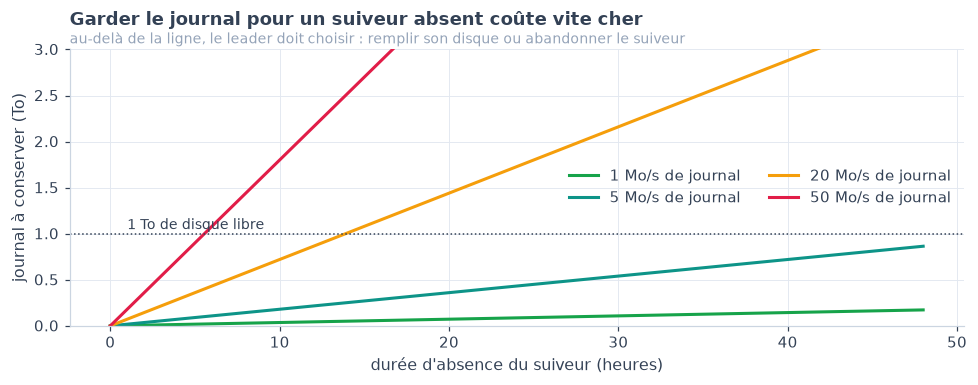

In [9]:
debit_mo_s = np.array([1, 5, 20, 50])              # volume de journal produit (Mo/s)
absence_h = np.linspace(0, 48, 200)
fig, ax = plt.subplots(figsize=(9, 3.6))
for v, c in zip(debit_mo_s, [GREEN, TEAL, AMBER, ROSE]):
    ax.plot(absence_h, v * absence_h * 3600 / 1e6, color=c, label=f"{v} Mo/s de journal")
ax.axhline(1.0, color=SLATE, ls=":", lw=1); ax.text(1, 1.05, "1 To de disque libre", fontsize=9)
ax.set_ylim(0, 3)
ax.set_xlabel("durée d'absence du suiveur (heures)"); ax.set_ylabel("journal à conserver (To)")
ax.set_title("Garder le journal pour un suiveur absent coûte vite cher")
subtitle(ax, "au-delà de la ligne, le leader doit choisir : remplir son disque ou abandonner le suiveur")
ax.legend(ncol=2)
plt.tight_layout(); plt.show()

À 20 Mo/s, un To de disque libre tient moins de 14 heures : un suiveur parti pour le
week-end sera reconstruit plutôt que rattrapé (PostgreSQL règle ce choix avec les
*replication slots* et `max_slot_wal_keep_size`).

> **À retenir.** Un suiveur qui redémarre reprend à sa dernière position du journal.
> C'est le cas facile ; il a pourtant un coût (charge de rattrapage, rétention du
> journal sur le leader).

## 5. Panne du leader : le basculement (section *Leader failure: Failover*)

Si le leader tombe, il faut **promouvoir** un suiveur, rediriger les clients vers lui et
brancher les autres suiveurs sur son journal : c'est le **basculement** (failover).
Automatisé, il comporte trois étapes :

1. **constater** que le leader est mort : aucune méthode infaillible, on utilise un
   **délai d'expiration** (pas de battement de cœur depuis, disons, 30 s) ;
2. **choisir** un nouveau leader : par élection (problème de consensus, chapitre
   9) ou par un **contrôleur** désigné à l'avance ; le meilleur candidat
   est le suiveur **le plus à jour** ;
3. **reconfigurer** : clients et suiveurs parlent au nouveau leader, et l'ancien, s'il
   revient, doit accepter de redevenir suiveur.

Le module implémente cette mécanique : un contrôleur reçoit les battements du leader
`n1` ; au-delà de 2 unités de silence, il interroge les suiveurs sur leur position et
promeut le plus avancé. La réplication est **asynchrone** et le journal part vers `n2`
avec 0,5 unité de retard, vers `n3` avec 1,5 (suiveur lointain). Le leader tombe à t = 6.

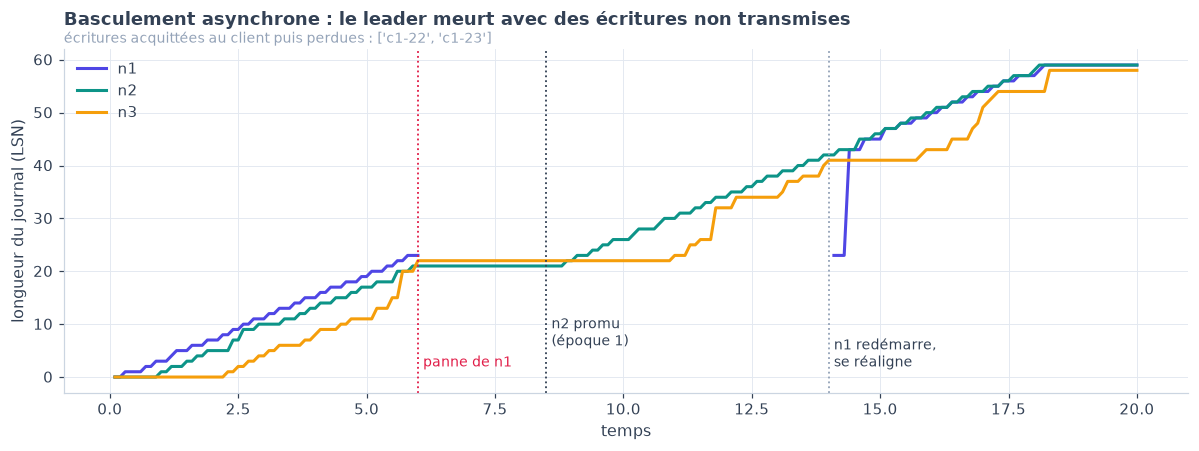

,requête,LSN sur l'ancien leader,acquittée au client
0,c1-22,22,True
1,c1-23,23,True


In [10]:
SHIP = {"n2": 0.5, "n3": 1.5}
res = rp.failover_scenario("async", "crash", t_fault=6.0, t_heal=14.0, until=20, ship_delay=SHIP,
                           period=0.25, seed=0)
ts = np.array([s[0] for s in res["samples"]])
fig, ax = plt.subplots(figsize=(11, 4.2))
for n, c in [("n1", INDIGO), ("n2", TEAL), ("n3", AMBER)]:
    l = np.array([s[1][n] for s in res["samples"]], dtype=float)
    down = np.array([s[2][n] == "panne" for s in res["samples"]])
    ax.plot(ts, np.where(down, np.nan, l), color=c, label=n, lw=2)
ax.axvline(6.0, color=ROSE, ls=":", lw=1.2); ax.text(6.1, 2, "panne de n1", color=ROSE, fontsize=9)
t_fo, new, ep = res["controller"].failovers[0]
ax.axvline(t_fo, color=SLATE, ls=":", lw=1.2); ax.text(t_fo + 0.1, 6, f"{new} promu\n(époque {ep})", fontsize=9)
ax.axvline(14.0, color=GRAY, ls=":", lw=1.2); ax.text(14.1, 2, "n1 redémarre,\nse réaligne", fontsize=9, color=SLATE)
ax.set_xlabel("temps"); ax.set_ylabel("longueur du journal (LSN)")
ax.set_title("Basculement asynchrone : le leader meurt avec des écritures non transmises")
subtitle(ax, f"écritures acquittées au client puis perdues : {res['lost']}")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
lost = [e for e in res["nodes"]["n1"].discarded]
pd.DataFrame([{"requête": e.req, "LSN sur l'ancien leader": e.lsn, "acquittée au client": e.req in res["client"].acked}
              for e in lost])

Au moment de la panne, `n1` avait acquitté des écritures dont le journal n'était pas
encore parti vers `n2` (retard d'expédition de 0,5) : elles n'existent que sur son disque.
Le contrôleur a bien promu le suiveur le plus avancé, `n2`, mais il lui manque ces
entrées. Au redémarrage, `n1` découvre qu'une époque plus récente existe, redevient
suiveur et **jette** ce qu'il était seul à avoir : le client avait pourtant reçu « ok ».
C'est la solution la plus courante, et c'est une perte de **durabilité**.

**Choisir le plus à jour compte.** Rejouons la même panne sur 60 graines, en promouvant
le suiveur le plus avancé ou un suiveur au hasard, pour chaque mode de réplication.

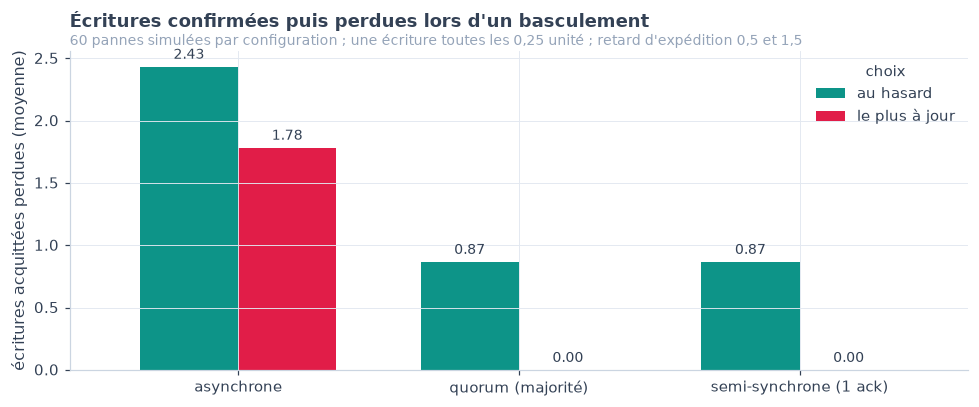

choix,au hasard,le plus à jour
mode,,
asynchrone,2.433,1.783
quorum (majorité),0.867,0.000
semi-synchrone (1 ack),0.867,0.000


In [11]:
rows = []
for mode in ["async", "semisync", "quorum"]:
    for policy in ["best", "random"]:
        for seed in range(60):
            r = rp.failover_scenario(mode, "crash", ship_delay=SHIP, policy=policy, period=0.25, seed=seed)
            rows.append({"mode": modes[mode], "choix": {"best": "le plus à jour", "random": "au hasard"}[policy],
                         "écritures perdues": len(r["lost"])})
P = pd.DataFrame(rows).groupby(["mode", "choix"])["écritures perdues"].mean().unstack()
ax = P.plot.bar(figsize=(9, 3.8), color=[TEAL, ROSE], rot=0, width=0.7)
annotate_bars(ax, "{:.2f}")
ax.set_ylabel("écritures acquittées perdues (moyenne)"); ax.set_xlabel("")
ax.set_title("Écritures confirmées puis perdues lors d'un basculement")
subtitle(ax, "60 pannes simulées par configuration ; une écriture toutes les 0,25 unité ; retard d'expédition 0,5 et 1,5")
plt.tight_layout(); plt.show()
P

En asynchrone, promouvoir un suiveur au hasard perd en moyenne bien plus d'écritures, car
le suiveur lointain `n3` a 1,5 unité de retard. En semi-synchrone ou par quorum, **rien**
n'est perdu quand on choisit le plus à jour : toute écriture acquittée est sur au moins
un suiveur, et le contrôleur promeut celui qui l'a. Encore faut-il que le contrôleur
connaisse les positions : il décide sur la foi de réponses qui peuvent arriver en
retard, et si celle du suiveur le plus avancé arrivait après sa décision, il en
promouvrait un autre (le module attend 0,75 unité avant de trancher).
Avec un choix au hasard, même le
semi-synchrone peut perdre (le suiveur synchrone n'est pas celui qu'on promeut) : il
faut promouvoir **le** suiveur que le leader attendait.

**Quel délai d'expiration ?** Trop long, l'indisponibilité dure ; trop court, on bascule
pour rien lors d'un pic de charge ou d'un hoquet réseau, et un basculement inutile
aggrave souvent la situation. Modélisons le délai entre deux battements reçus par le
contrôleur : 1 s nominal, une gigue log-normale, et des pics de charge où le leader met
jusqu'à 20 s à répondre (en moyenne 3 pics par jour).

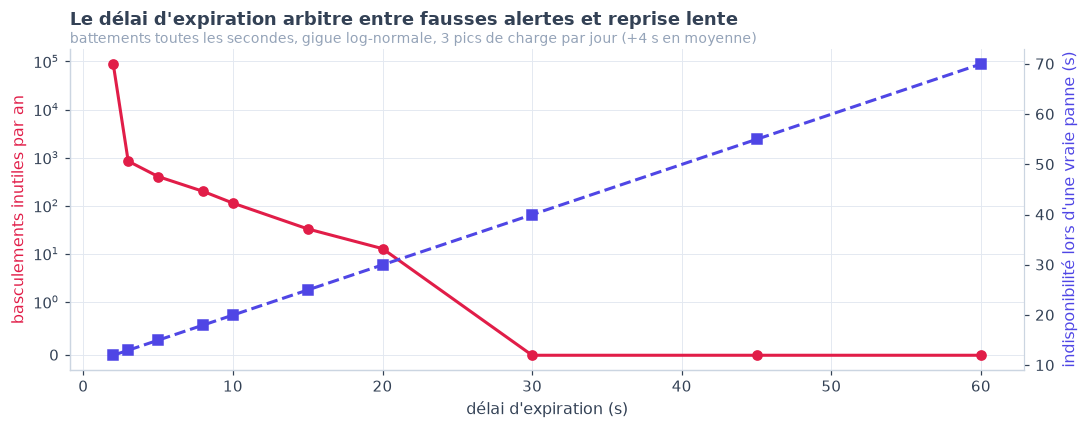

délai (s),2,3,5,8,10,15,20,30,45,60
basculements inutiles / an,88399.4,843.2,403.3,198.9,113.2,32.8,12.8,0.0,0.0,0.0


In [12]:
def faux_basculements_par_an(timeout, rng, jours=200):
    n = int(jours * 86400)                       # un battement par seconde
    gaps = 1.0 * rng.lognormal(0, 0.25, n)
    k = rng.poisson(3 * jours)
    idx = rng.integers(0, n, k)
    gaps[idx] += rng.exponential(4.0, k)         # pics de charge
    return (gaps > timeout).sum() * 365 / jours

timeouts = np.array([2, 3, 5, 8, 10, 15, 20, 30, 45, 60])
faux = np.array([faux_basculements_par_an(t, np.random.default_rng(1)) for t in timeouts])
indispo = timeouts + 10                          # détection + ~10 s pour élire et reconfigurer
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(timeouts, faux, "o-", color=ROSE, label="basculements inutiles par an")
ax1.set_yscale("symlog", linthresh=1); ax1.set_ylabel("basculements inutiles par an", color=ROSE)
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(timeouts, indispo, "s--", color=INDIGO, label="indisponibilité par vraie panne (s)")
ax2.set_ylabel("indisponibilité lors d'une vraie panne (s)", color=INDIGO)
ax2.spines["right"].set_visible(True)
ax1.set_xlabel("délai d'expiration (s)")
ax1.set_title("Le délai d'expiration arbitre entre fausses alertes et reprise lente")
subtitle(ax1, "battements toutes les secondes, gigue log-normale, 3 pics de charge par jour (+4 s en moyenne)")
plt.tight_layout(); plt.show()
pd.DataFrame({"délai (s)": timeouts, "basculements inutiles / an": faux.round(1)}).set_index("délai (s)").T

Avec 2 s, la gigue ordinaire suffit à déclencher des dizaines de milliers de fausses
alertes par an ; entre 3 et 10 s, il en reste des centaines (chaque pic de charge en
provoque une) ; vers 15-20 s, une à trois par mois, pour une demi-minute
d'indisponibilité à chaque vraie panne ; à partir de 30 s, plus aucune dans cette
simulation, mais chaque panne réelle coûte 40 s ou plus. Il n'y a
pas de bonne valeur universelle : elle dépend de la distribution des délais **de votre
système**, d'où l'importance de la mesurer (chapitre 8). Cette difficulté
explique que certaines équipes préfèrent déclencher le basculement **à la main**.

> **À retenir.** Un basculement automatique détecte la panne par un délai, promeut le
> suiveur le plus à jour et réaligne l'ancien leader. En asynchrone, il perd les
> écritures que le leader était seul à avoir, même acquittées ; le délai d'expiration
> arbitre entre indisponibilité et basculements inutiles.

## 6. Split brain, fencing et clés réutilisées (section *Handling Node Outages*)

**Split brain.** Une panne n'est pas toujours franche. Coupons le réseau entre d'un côté
le leader `n1` et le client `c1`, de l'autre le contrôleur et les suiveurs. Pour le
contrôleur, `n1` est mort : il promeut `n2`. Mais `n1` est bien vivant et continue
d'accepter les écritures de `c1` : deux nœuds se croient leaders. À la guérison, il
faut en sacrifier un. Comparons la réplication asynchrone et le quorum.

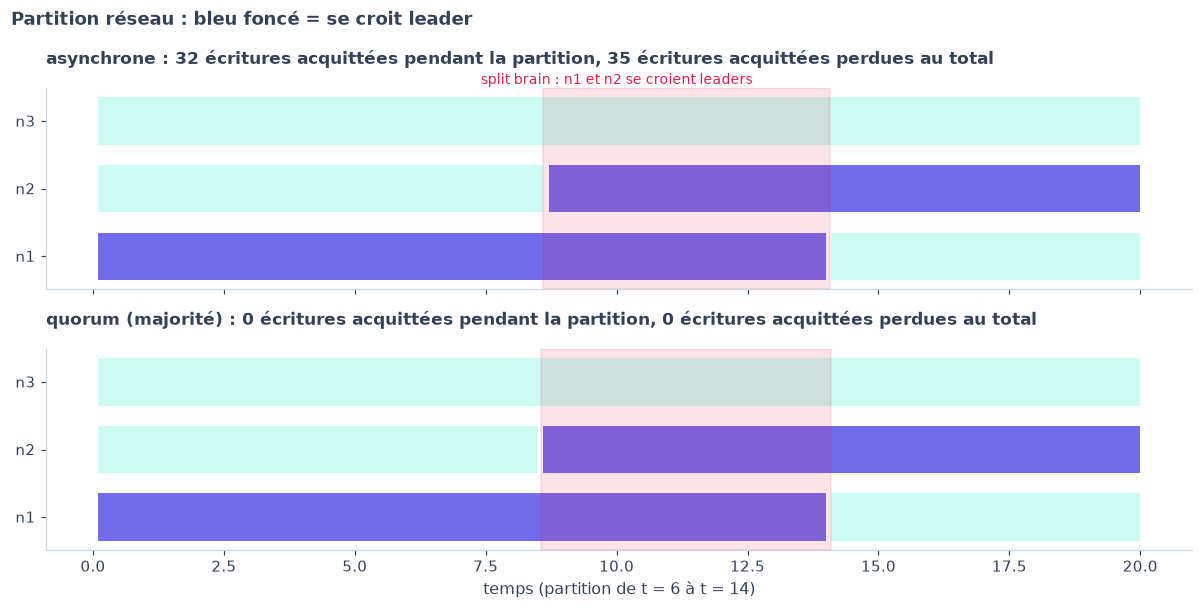

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
for ax, mode in zip(axes, ["async", "quorum"]):
    r = rp.failover_scenario(mode, "partition", t_fault=6, t_heal=14, until=20, ship_delay=SHIP,
                             period=0.25, seed=1)
    ts = np.array([s[0] for s in r["samples"]])
    for i, n in enumerate(["n1", "n2", "n3"]):
        roles = [s[2][n] for s in r["samples"]]
        is_leader = np.array([x == "leader" for x in roles])
        ax.fill_between(ts, i - 0.35, i + 0.35, where=is_leader, color=INDIGO, alpha=0.8, step="mid", lw=0)
        ax.fill_between(ts, i - 0.35, i + 0.35, where=~is_leader, color=LIGHT[TEAL], step="mid", lw=0)
    for (a_, b_) in (r["split_brain"] or []):
        ax.axvspan(a_, b_, color=ROSE, alpha=0.12)
    acked_part = [k for k, v in r["client"].acked.items() if 6 <= r["client"].sent[k] < 14]
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["n1", "n2", "n3"])
    ax.grid(False)
    ax.set_title(f"{modes[mode]} : {len(acked_part)} écritures acquittées pendant la partition, "
                 f"{len(r['lost'])} écritures acquittées perdues au total", fontsize=11)
axes[0].text(10, 2.55, "split brain : n1 et n2 se croient leaders", ha="center", color=ROSE, fontsize=9)
axes[1].set_xlabel("temps (partition de t = 6 à t = 14)")
fig.suptitle("Partition réseau : bleu foncé = se croit leader", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

En **asynchrone**, l'ancien leader isolé acquitte toutes les écritures de `c1` pendant
huit unités de temps ; à la guérison, il apprend l'existence de l'époque 1, redevient
suiveur et jette ces écritures, plus les quelques-unes acquittées juste avant la coupure
et pas encore expédiées : le client a été trompé plus de trente fois. Avec un
**quorum**, l'ancien leader est toujours persuadé d'être leader (le split brain existe
encore dans sa tête), mais il ne peut réunir aucun acquittement : il ne confirme rien,
donc il ne ment pas. C'est l'idée qui fonde le consensus (chapitre 9).

**Fencing.** Pour se protéger d'un ancien leader, on lui **coupe l'accès** : les
suiveurs refusent tout message portant une époque (un « numéro de génération »)
inférieure à la leur, et l'ancien leader qui reçoit ce refus se rétrograde (dans le
module : message `("reject", epoch)`). Les mécanismes plus brutaux, qui éteignent un
nœud quand deux leaders sont détectés (STONITH, *shoot the other node in the head*),
doivent être conçus avec soin : mal faits, ils éteignent les deux. Le chapitre
8 y revient avec les baux et les jetons de fencing.

**Quand d'autres systèmes dépendent de la base.** Jeter des écritures est encore plus
grave si un système extérieur les a vues. Le livre cite un incident de GitHub (2012) :
un suiveur MySQL en retard est promu ; son compteur d'auto-incrément est en retard sur
celui de l'ancien leader, il **réattribue** des clés primaires déjà utilisées ; or ces
clés servaient aussi dans un cache Redis, qui a alors servi des données privées aux
mauvais utilisateurs. Rejouons-le avec la mini-base `rp.MiniDB`.

In [14]:
leader, suiveur = rp.MiniDB("leader"), rp.MiniDB("suiveur")
cache = {}                                       # système externe : id -> propriétaire du document
for i, user in enumerate(["alice", "bob", "carole", "david", "emma", "farid"]):
    pk = leader.insert("documents", {"owner": user, "titre": f"note privée de {user}"})
    cache[pk] = user                             # le cache est alimenté depuis le leader
    if i < 4:                                    # réplication asynchrone : le suiveur n'a reçu que 4 lignes
        suiveur.apply_change(leader.changes[-1])
# panne du leader, promotion du suiveur ; deux nouvelles insertions
nouveaux = [suiveur.insert("documents", {"owner": u, "titre": f"note privée de {u}"}) for u in ["gina", "hugo"]]
rows = []
for pk in nouveaux:
    rows.append({"id attribué": pk, "propriétaire réel (nouvelle base)": suiveur.tables["documents"][pk]["owner"],
                 "propriétaire selon le cache": cache[pk]})
pd.DataFrame(rows)

,id attribué,propriétaire réel (nouvelle base),propriétaire selon le cache
0,5,gina,emma
1,6,hugo,farid


Les identifiants 5 et 6, déjà donnés par l'ancien leader à emma et farid, sont réattribués
à gina et hugo. Le cache, qui n'a pas été « rembobiné » avec la base, associe désormais
ces clés aux anciens propriétaires : selon le côté par lequel on interroge, gina voit la
note d'emma, ou emma celle de gina. Une écriture perdue n'est pas seulement une donnée
en moins, elle peut **casser les invariants** des systèmes qui l'avaient lue.

> **À retenir.** Une partition peut créer deux leaders (split brain). On s'en protège en
> n'acquittant qu'avec un quorum et en refusant les ordres d'une époque périmée
> (fencing). Les écritures jetées par un basculement peuvent corrompre les systèmes
> externes qui les avaient vues, comme dans l'incident GitHub.

## Synthèse

- La réplication à leader unique fait passer toutes les écritures par un nœud qui fixe
  leur ordre et le diffuse dans un journal ; les suiveurs l'appliquent à l'identique.
- Synchrone ou asynchrone : la latence et la disponibilité des écritures dépendent des
  suiveurs qu'on attend (statistiques d'ordre). Le semi-synchrone et le quorum
  n'attendent que les plus rapides et gardent une copie à jour.
- Un suiveur se monte par instantané repéré dans le journal, puis rattrapage ; il se
  remet d'une panne en reprenant à sa dernière position.
- Le basculement est le moment dangereux : détection par délai (fausses alertes contre
  reprise lente), promotion du plus à jour, écritures acquittées perdues en asynchrone,
  split brain lors d'une partition, d'où le fencing par époque et les quorums.

Liens : le cours 2 ouvre le capot du journal de réplication et étudie les anomalies
dues au **retard** des suiveurs ; les problèmes de détection de panne, de délais et de
baux sont approfondis au chapitre 8, l'élection sûre d'un leader au chapitre
9 ; le journal d'écriture anticipée vient du chapitre 3.